# Complaint2Concern
## Using pretrained complaint embeddings to catch acuity-relevant risk that structured triage may miss

### Clinical motivation
- Emergency triage decisions are safety-critical, and undertriage is often the most harmful error type.
- Structured intake fields are useful but may miss concern signals present in free-text chief complaint language.
- We use pretrained complaint embeddings as a second clinical lens and analyze disagreement with structured-only predictions.

### Hypothesis
Pretrained complaint embeddings improve acuity prediction and help identify cases where free text suggests more urgency than structured intake alone.

### Core questions
1. Does complaint text improve triage acuity prediction beyond structured features?
2. Which complaint clusters are associated with higher acuity?
3. Can text-vs-structure disagreement identify review-worthy cases?

## Data understanding and leakage guardrails

This is a triage-time task. All model inputs must be available at triage decision time.

- Allowed: intake structured variables, chief complaint text, prior history available at triage.
- Excluded as leakage: post-triage outcomes (for example `disposition`, `ed_los_hours`).

Missingness is handled with model pipelines (median/mode imputation in structured preprocessing).

In [1]:
import os
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd

from scipy.sparse import csr_matrix, hstack
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

try:
    import matplotlib.pyplot as plt
    MATPLOTLIB_OK = True
except Exception:
    MATPLOTLIB_OK = False

# Resolve project root (works in local Jupyter and in Kaggle if repo is copied).
candidates = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = None
for c in candidates:
    if (c / 'src').exists() and (c / 'configs').exists():
        PROJECT_ROOT = c
        break
if PROJECT_ROOT is None:
    raise RuntimeError('Could not locate PROJECT_ROOT with src/ and configs/.')

sys.path.append(str(PROJECT_ROOT))
print('PROJECT_ROOT:', PROJECT_ROOT)

PROJECT_ROOT: /Users/raquel_romao/Documents/3AIG_TriageKeggleCompetition/3AIG


In [2]:
from src.config import load_config
from src.data_io import load_train_test
from src.embeddings import encode_complaints
from src.features_structured import fit_transform_structured, infer_structured_columns
from src.features_text import fit_transform_tfidf
from src.preprocess import preprocess_text_series
from src.utils import make_classifier, set_seed

In [ ]:
# Config
cfg = load_config(PROJECT_ROOT / 'configs/minilm_catboost.yaml')

# Optional Kaggle path override example:
# cfg['data']['kaggle_input_dir'] = '/kaggle/input/triagegeist'

DEV_SAMPLE_N = None  # Set an integer like 20000 for quick local iteration.
SEED = cfg['train'].get('seed', 42)
set_seed(SEED)

#merges original train and test to complaint text by patient id
train_df, test_df = load_train_test(cfg)
if DEV_SAMPLE_N is not None and DEV_SAMPLE_N < len(train_df):
    train_df = train_df.sample(DEV_SAMPLE_N, random_state=SEED).reset_index(drop=True)

id_col = cfg['data']['id_col']
target_col = cfg['data']['target_col']
text_col = cfg['data']['text_col']
leakage_cols = cfg['data'].get('leakage_columns', [])

print('train shape:', train_df.shape)
print('test shape :', test_df.shape)
print('target col :', target_col)
print('text col   :', text_col)
print('null text train:', round(train_df[text_col].isna().mean(), 4))
print('null text test :', round(test_df[text_col].isna().mean(), 4))

train shape: (80000, 66)
test shape : (20000, 63)
target col : triage_acuity
text col   : chief_complaint_raw
null text train: 0.0
null text test : 0.0


Acuity distribution (train):


triage_acuity
1    0.040275
2    0.167988
3    0.361513
4    0.287750
5    0.142475
Name: proportion, dtype: float64

,missing_rate
shock_index,0.051825
pulse_pressure,0.051825
systolic_bp,0.051825
diastolic_bp,0.051825
mean_arterial_pressure,0.051825
respiratory_rate,0.038337
temperature_c,0.007175
hx_diabetes_type2,0.000000
hx_diabetes_type1,0.000000
disposition,0.000000


,heart_rate,respiratory_rate,temperature_c,spo2,systolic_bp,diastolic_bp,news2_score
triage_acuity,,,,,,,
1,119.2,28.0,38.9,85.9,82.6,52.15,14.0
2,108.7,23.0,38.5,92.0,100.4,63.30,10.0
3,93.0,18.0,37.7,96.0,126.0,76.90,2.0
4,84.1,16.0,37.2,98.0,132.0,80.00,0.0
5,76.8,15.0,36.9,99.0,128.1,78.80,0.0


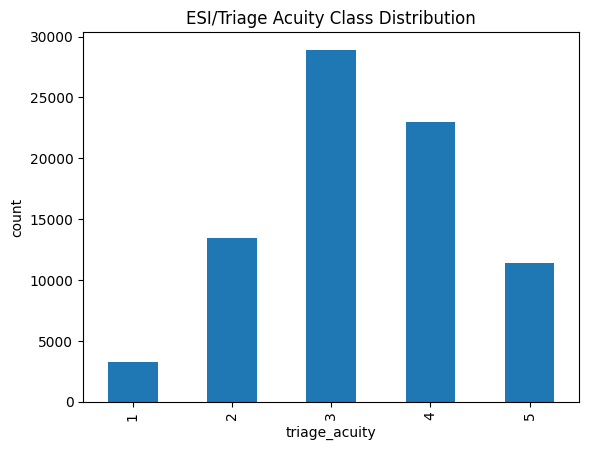

In [4]:
# Triage-focused EDA
print('Acuity distribution (train):')
display(train_df[target_col].value_counts(normalize=True).sort_index())

missingness = train_df.isna().mean().sort_values(ascending=False)
display(missingness.head(15).to_frame('missing_rate'))

# Vitals by acuity (median)
vitals = [c for c in ['heart_rate','respiratory_rate','temperature_c','spo2','systolic_bp','diastolic_bp','news2_score'] if c in train_df.columns]
if vitals:
    display(train_df.groupby(target_col)[vitals].median())

if MATPLOTLIB_OK:
    ax = train_df[target_col].value_counts().sort_index().plot(kind='bar', title='ESI/Triage Acuity Class Distribution')
    ax.set_xlabel('triage_acuity')
    ax.set_ylabel('count')
    plt.show()

## Complaint text preprocessing

We keep preprocessing lightweight and realistic for triage text:
- lowercase
- punctuation and whitespace cleanup
- optional normalization of common abbreviations
- keep most spelling noise intact to preserve realistic inputs

In [5]:
ABBREV_MAP = {
    'sob': 'shortness of breath',
    'cp': 'chest pain',
    'ha': 'headache',
    'n/v': 'nausea vomiting',
}

def normalize_abbrev(text: str) -> str:
    t = '' if text is None else str(text).lower()
    for k, v in ABBREV_MAP.items():
        t = re.sub(rf'\b{re.escape(k)}\b', v, t)
    return t

train_df[text_col] = train_df[text_col].fillna('').map(normalize_abbrev)
test_df[text_col] = test_df[text_col].fillna('').map(normalize_abbrev)

display(train_df[[text_col]].head(10))

,chief_complaint_raw
0,"thunderclap headache, worsening with movement"
1,"contraception advice, intermittent"
2,"general health question, intermittent"
3,"erythema migrans tick bite, intermittent"
4,"cellulitis localised, intermittent"
5,shingles with pain with associated nausea
6,minor skin rash with rigors
7,substance intoxication，worsening over hours
8,"small cut wound check, intermittent"
9,minor facial laceration with rigors


In [6]:
# Prepare split
label_encoder = LabelEncoder()
y_all = label_encoder.fit_transform(train_df[target_col].astype(str))

train_idx, valid_idx = train_test_split(
    np.arange(len(train_df)),
    test_size=cfg['train'].get('valid_size', 0.2),
    random_state=SEED,
    stratify=y_all,
)

tr = train_df.iloc[train_idx].reset_index(drop=True)
va = train_df.iloc[valid_idx].reset_index(drop=True)
y_tr = y_all[train_idx]
y_va = y_all[valid_idx]

print('train split:', tr.shape)
print('valid split:', va.shape)

train split: (64000, 66)
valid split: (16000, 66)


In [7]:
# Structured feature preprocessing
structured_cols = infer_structured_columns(
    tr,
    target_col=target_col,
    text_col=text_col,
    id_col=id_col,
    explicit_drop_cols=leakage_cols,
)

structured_pre, x_tr_struct, x_va_struct = fit_transform_structured(tr[structured_cols], va[structured_cols])
print('structured feature count:', x_tr_struct.shape[1])

structured feature count: 178


In [8]:
tr

,patient_id,site_id,triage_nurse_id,arrival_mode,arrival_hour,arrival_day,arrival_month,arrival_season,shift,age,...,hx_hypothyroidism,hx_hyperthyroidism,hx_hiv,hx_coagulopathy,hx_immunosuppressed,hx_pregnant,hx_substance_use_disorder,hx_coronary_artery_disease,hx_stroke_prior,hx_peripheral_vascular_disease
0,TG-YATJJEFE1,SITE-TUR-01,NURSE-0030,walk-in,7,Wednesday,10,autumn,morning,73,...,0,0,0,1,0,0,0,1,0,1
1,TG-NME87NPJQ,SITE-TUR-01,NURSE-0048,ambulance,8,Tuesday,8,summer,morning,15,...,0,0,0,1,0,0,0,0,0,0
2,TG-DECREJ81P,SITE-OUL-01,NURSE-0012,walk-in,23,Sunday,8,summer,evening,80,...,0,0,1,0,0,0,1,0,1,1
3,TG-3WKP17TNF,SITE-TMP-01,NURSE-0016,brought_by_family,12,Tuesday,1,winter,morning,24,...,0,0,0,0,0,0,0,0,0,1
4,TG-4F0NH86XR,SITE-HEL-01,NURSE-0002,walk-in,4,Monday,9,autumn,night,47,...,0,1,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63995,TG-VZIEY3RUK,SITE-TUR-01,NURSE-0023,brought_by_family,2,Thursday,3,spring,night,54,...,0,0,0,0,0,0,0,0,0,0
63996,TG-0VVUELDGI,SITE-HEL-01,NURSE-0039,ambulance,13,Wednesday,5,spring,morning,26,...,1,0,0,1,0,0,0,0,1,0
63997,TG-SW6AZNQTZ,SITE-TUR-01,NURSE-0006,ambulance,5,Friday,10,autumn,night,45,...,0,0,0,0,0,0,0,0,1,0
63998,TG-ECS44SOF5,SITE-TUR-01,NURSE-0031,walk-in,18,Sunday,10,autumn,afternoon,71,...,0,0,1,0,1,0,0,0,1,0


## Baselines and fusion models

We train and compare:
1. Structured-only
2. Text-only (TF-IDF + linear model)
3. Structured + TF-IDF
4. Text-only pretrained embeddings
5. Structured + pretrained embeddings (Complaint2Concern fusion)

In [10]:
import sklearn, inspect
from sklearn.linear_model import LogisticRegression
print("sklearn:", sklearn.__version__)
print("class:", LogisticRegression)
print("signature:", inspect.signature(LogisticRegression))

sklearn: 1.8.0
class: <class 'sklearn.linear_model._logistic.LogisticRegression'>
signature: (penalty='deprecated', *, C=1.0, l1_ratio=0.0, dual=False, tol=0.0001, fit_intercept=True, intercept_scaling=1, class_weight=None, random_state=None, solver='lbfgs', max_iter=100, verbose=0, warm_start=False, n_jobs=None)


In [12]:
# 1) Structured-only
structured_model = make_classifier(
    model_name='catboost',
    params={'iterations': 350, 'depth': 6, 'learning_rate': 0.05, 'verbose': False},
    n_classes=len(label_encoder.classes_),
)
structured_model.fit(x_tr_struct, y_tr)
pred_struct = np.asarray(structured_model.predict(x_va_struct)).reshape(-1).astype(int)
proba_struct = np.asarray(structured_model.predict_proba(x_va_struct))

# 2) Text-only TF-IDF + linear model
tfidf_vec, x_tr_tfidf, x_va_tfidf = fit_transform_tfidf(
    tr[text_col],
    va[text_col],
    max_features=25000,
    ngram_range=(1, 2),
)
tfidf_model = LogisticRegression(max_iter=1200, solver="lbfgs")
tfidf_model.fit(x_tr_tfidf, y_tr)
pred_tfidf = tfidf_model.predict(x_va_tfidf).astype(int)
proba_tfidf = tfidf_model.predict_proba(x_va_tfidf)

# 3) Structured + TF-IDF
x_tr_struct_sparse = csr_matrix(x_tr_struct)
x_va_struct_sparse = csr_matrix(x_va_struct)
x_tr_struct_tfidf = hstack([x_tr_struct_sparse, x_tr_tfidf]).tocsr()
x_va_struct_tfidf = hstack([x_va_struct_sparse, x_va_tfidf]).tocsr()
struct_tfidf_model = LogisticRegression(max_iter=1200, solver="lbfgs")
struct_tfidf_model.fit(x_tr_struct_tfidf, y_tr)
pred_struct_tfidf = struct_tfidf_model.predict(x_va_struct_tfidf).astype(int)
proba_struct_tfidf = struct_tfidf_model.predict_proba(x_va_struct_tfidf)

In [13]:
# 4) Text-only pretrained embeddings
emb_model_name = cfg['embeddings'].get('model_name', 'sentence-transformers/all-MiniLM-L6-v2')
emb_batch_size = cfg['embeddings'].get('batch_size', 64)

x_tr_emb = encode_complaints(tr[text_col], model_name=emb_model_name, batch_size=emb_batch_size)
x_va_emb = encode_complaints(va[text_col], model_name=emb_model_name, batch_size=emb_batch_size)

emb_text_model = make_classifier(
    model_name='lightgbm',
    params={'n_estimators': 350, 'learning_rate': 0.05, 'num_leaves': 63},
    n_classes=len(label_encoder.classes_),
)
emb_text_model.fit(x_tr_emb, y_tr)
pred_emb_text = np.asarray(emb_text_model.predict(x_va_emb)).reshape(-1).astype(int)
proba_emb_text = np.asarray(emb_text_model.predict_proba(x_va_emb))

# 5) Structured + pretrained embeddings (main fusion)
x_tr_fusion = np.hstack([x_tr_struct, x_tr_emb])
x_va_fusion = np.hstack([x_va_struct, x_va_emb])
fusion_model = make_classifier(
    model_name='catboost',
    params={'iterations': 450, 'depth': 6, 'learning_rate': 0.05, 'verbose': False},
    n_classes=len(label_encoder.classes_),
)
fusion_model.fit(x_tr_fusion, y_tr)
pred_fusion = np.asarray(fusion_model.predict(x_va_fusion)).reshape(-1).astype(int)
proba_fusion = np.asarray(fusion_model.predict_proba(x_va_fusion))

/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 17872.47it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7248.30it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.032547 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 97920
[LightGBM] [Info] Number of data points in the train set: 64000, number of used features: 384
[LightGBM] [Info] Start training from score -3.211869
[LightGBM] [Info] Start training from score -1.783884
[LightGBM] [Info] Start training from score -1.017450
[LightGBM] [Info] Start training from score -1.245663
[LightGBM] [Info] Start training from score -1.948633
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best 

/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/triagegeist/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [14]:
# ESI-aware evaluation helpers
def decode(enc):
    return label_encoder.inverse_transform(np.asarray(enc).astype(int))

def to_int_labels(labels):
    return np.asarray(labels).astype(int)

def off_by_one_acc(y_true_int, y_pred_int):
    return float(np.mean(np.abs(y_true_int - y_pred_int) <= 1))

def eval_esi(y_true_enc, y_pred_enc):
    y_true_int = to_int_labels(decode(y_true_enc))
    y_pred_int = to_int_labels(decode(y_pred_enc))
    return {
        'accuracy': float(np.mean(y_true_enc == y_pred_enc)),
        'macro_f1': float(f1_score(y_true_enc, y_pred_enc, average='macro')),
        'off_by_1': off_by_one_acc(y_true_int, y_pred_int),
        'undertriage_rate': float(np.mean(y_pred_int > y_true_int)),
        'severe_undertriage_rate': float(np.mean((y_pred_int - y_true_int) >= 2)),
        'recall_esi_1_2': float(np.mean(y_pred_int[y_true_int <= 2] <= 2)) if np.any(y_true_int <= 2) else np.nan,
    }

rows = [
    {'model': 'structured_only', **eval_esi(y_va, pred_struct)},
    {'model': 'text_tfidf_only', **eval_esi(y_va, pred_tfidf)},
    {'model': 'structured_plus_tfidf', **eval_esi(y_va, pred_struct_tfidf)},
    {'model': 'text_emb_only', **eval_esi(y_va, pred_emb_text)},
    {'model': 'structured_plus_emb_fusion', **eval_esi(y_va, pred_fusion)},
]
perf_df = pd.DataFrame(rows).sort_values('macro_f1', ascending=False)
display(perf_df)

,model,accuracy,macro_f1,off_by_1,undertriage_rate,severe_undertriage_rate,recall_esi_1_2
1,text_tfidf_only,0.999188,0.997478,1.000000,0.000812,0.000000,1.000000
3,text_emb_only,0.999125,0.997283,1.000000,0.000875,0.000000,1.000000
2,structured_plus_tfidf,0.997625,0.994300,0.999938,0.001813,0.000063,0.996999
4,structured_plus_emb_fusion,0.995062,0.992100,0.999875,0.004000,0.000063,0.988595
0,structured_only,0.852563,0.869685,0.998250,0.081125,0.001313,0.979292


- macro-F1: balance across classes (important if imbalanced).
  - undertriage/severe undertriage: safety-critical.
  - recall ESI 1-2: ability to catch urgent patients.

Safety-oriented metrics are strong for text models (very low undertriage), while structured-only undertriage is much higher (~0.081).

text_tfidf_only and text_emb_only are top (macro_f1 ~0.997), while structured_only is much lower (macro_f1 ~0.870).  
  This suggests the chief complaint text carries a very strong acuity signal in this dataset.

fusion model (structured_plus_emb_fusion) is good but worse than text-only in this run (macro_f1 ~0.992 vs ~0.997 for text-only).  
- So right now, adding structured features does not improve predictive performance.

In [15]:
# Confusion matrix (fusion)
y_true_int = to_int_labels(decode(y_va))
y_pred_fusion_int = to_int_labels(decode(pred_fusion))
cm = pd.crosstab(
    pd.Series(y_true_int, name='true_acuity'),
    pd.Series(y_pred_fusion_int, name='pred_acuity'),
    dropna=False,
)
display(cm)

pred_acuity,1,2,3,4,5
true_acuity,,,,,
1,620,24,0,0,0
2,2,2648,38,0,0
3,0,8,5774,1,1
4,0,0,4,4600,0
5,0,0,1,0,2279


## Innovation layer: complaint-structure mismatch

We define a Text Concern Gap using high-acuity probability mass (ESI 1-2):

`gap = P_text(ESI 1-2) - P_structured(ESI 1-2)`

Positive values indicate text model is more alarmed than structured-only model.

In [16]:
classes_int = np.asarray(label_encoder.classes_).astype(int)
high_mask = classes_int <= 2

p_high_text = proba_emb_text[:, high_mask].sum(axis=1)
p_high_struct = proba_struct[:, high_mask].sum(axis=1)
concern_gap = p_high_text - p_high_struct

mismatch_df = va[[id_col, text_col]].copy()
mismatch_df['true_acuity'] = y_true_int
mismatch_df['pred_structured'] = to_int_labels(decode(pred_struct))
mismatch_df['pred_text_emb'] = to_int_labels(decode(pred_emb_text))
mismatch_df['pred_fusion'] = y_pred_fusion_int
mismatch_df['p_high_text'] = p_high_text
mismatch_df['p_high_struct'] = p_high_struct
mismatch_df['text_concern_gap'] = concern_gap

gap_threshold = np.quantile(mismatch_df['text_concern_gap'], 0.90)
alert_cases = mismatch_df[mismatch_df['text_concern_gap'] >= gap_threshold].copy()

print('gap threshold (p90):', round(float(gap_threshold), 4))
print('alert case count:', len(alert_cases))
print('alert true high-acuity rate:', round((alert_cases['true_acuity'] <= 2).mean(), 4))

display(alert_cases.sort_values('text_concern_gap', ascending=False).head(20))

gap threshold (p90): 0.0018
alert case count: 1600
alert true high-acuity rate: 1.0


,patient_id,chief_complaint_raw,true_acuity,pred_structured,pred_text_emb,pred_fusion,p_high_text,p_high_struct,text_concern_gap
8847,TG-T39H3JPWE,"eczema herpeticum, onset today",2,3,2,3,1.000000,0.005760,0.994240
12845,TG-6BLNYI4W7,severe hypertensive emergency with rigors,2,3,2,3,1.000000,0.007610,0.992389
11803,TG-XGSZZJZFN,"significant blunt thoracic trauma, no prior hi...",2,3,2,3,1.000000,0.008161,0.991839
10995,TG-DSLTUOPPH,"acute upper gi bleed haematemesis, onset today",2,3,2,3,1.000000,0.009017,0.990983
4750,TG-M8MOP6BWH,near-drowning with diaphoresis,2,3,2,3,1.000000,0.025303,0.974697
10131,TG-KB3YD85JP,"aortic dissection suspected, since yesterday",2,3,2,3,1.000000,0.030353,0.969647
10578,TG-I7WMFCLS2,eczema herpeticum，worsening over hours,2,3,2,3,0.999999,0.034111,0.965888
15805,TG-YC1B5WT82,hypothermia moderate，worsening over hours,2,3,2,3,0.999999,0.034514,0.965486
12589,TG-R5I1AHEOH,"suicidal ideation with plan and intent, interm...",2,3,2,3,0.999999,0.035580,0.964419
10013,TG-7BCC1M3AE,"retinal detachment, for 2 days",2,3,2,3,1.000000,0.037898,0.962101


top text-concern-gap cases have high true high-acuity rate (alert true high-acuity rate: 1.0 in top-decile gap set).

Complaint clustering
- What it does:
  - clusters embedding vectors,
  - shows cluster-level high-acuity rates and sample complaints.
- Why it matters:
  - gives interpretable clinical themes.
- What to look for:
  - clusters with high acuity prevalence,
  - clusters with high concern-gap means.

In [17]:
# Complaint clustering and interpretation
n_clusters = 8
kmeans = KMeans(n_clusters=n_clusters, random_state=SEED, n_init=10)
cluster_id = kmeans.fit_predict(x_va_emb)

cluster_df = va[[text_col]].copy()
cluster_df['cluster'] = cluster_id
cluster_df['true_acuity'] = y_true_int
cluster_df['text_concern_gap'] = concern_gap

cluster_summary = cluster_df.groupby('cluster').agg(
    n=('cluster', 'size'),
    high_acuity_rate=('true_acuity', lambda s: np.mean(s <= 2)),
    mean_text_concern_gap=('text_concern_gap', 'mean'),
).sort_values('high_acuity_rate', ascending=False)
display(cluster_summary)

# Representative complaints: first few examples per cluster
examples = (
    cluster_df.groupby('cluster')[text_col]
    .apply(lambda s: list(s.head(5)))
    .to_frame('sample_complaints')
)
display(examples)

cluster_esi = pd.crosstab(cluster_df['cluster'], cluster_df['true_acuity'], normalize='index')
display(cluster_esi)

,n,high_acuity_rate,mean_text_concern_gap
cluster,,,
3,1797,0.328325,0.003598
0,1182,0.247885,0.002729
5,4089,0.216679,0.000709
7,2305,0.193926,-0.003090
2,1481,0.193113,-0.000631
6,1339,0.189694,-0.001049
1,2386,0.161777,-0.001889
4,1421,0.133709,-0.004017


,sample_complaints
cluster,
0,"[one week cough with diaphoresis, testicular t..."
1,"[severe migraine with photophobia, for 2 days,..."
2,"[severe migraine with photophobia with fever, ..."
3,"[fall from height significant mechanism, worse..."
4,"[otitis media with complications, worsening wi..."
5,"[overdose unknown substance, since yesterday, ..."
6,"[dysuria with systemic features with vomiting,..."
7,"[nasal congestion with vomiting, suspected den..."


true_acuity,1,2,3,4,5
cluster,,,,,
0,0.038917,0.208968,0.320643,0.296108,0.135364
1,0.029757,0.132020,0.371752,0.321039,0.145432
2,0.037812,0.155300,0.425388,0.277515,0.103984
3,0.077351,0.250974,0.381191,0.254869,0.035615
4,0.028149,0.105559,0.394792,0.288529,0.182970
5,0.041575,0.175104,0.319149,0.274639,0.189533
6,0.036594,0.153099,0.371173,0.297237,0.141897
7,0.031670,0.162256,0.364425,0.298482,0.143167


 Review-flag logic
- What it does:
  - flags cases with low fusion confidence or high concern gap.
- Why it matters:
  - converts model output into actionable triage support behavior.
- What to look for:
  - flagged set should be enriched for difficult/high-risk cases, not random.


In [18]:
# Review-flag logic (support tool, not auto-overrule)
pmax_fusion = proba_fusion.max(axis=1)
low_conf_threshold = np.quantile(pmax_fusion, 0.10)
high_gap_threshold = np.quantile(concern_gap, 0.90)

mismatch_df['fusion_confidence'] = pmax_fusion
mismatch_df['review_flag'] = (
    (mismatch_df['fusion_confidence'] <= low_conf_threshold)
    | (mismatch_df['text_concern_gap'] >= high_gap_threshold)
)

flagged = mismatch_df[mismatch_df['review_flag']]
print('review flag rate:', round(len(flagged) / len(mismatch_df), 4))
print('high-acuity rate among flagged:', round((flagged['true_acuity'] <= 2).mean(), 4))
display(flagged.head(20))

review flag rate: 0.1921
high-acuity rate among flagged: 0.5753


,patient_id,chief_complaint_raw,true_acuity,pred_structured,pred_text_emb,pred_fusion,p_high_text,p_high_struct,text_concern_gap,fusion_confidence,review_flag
1,TG-H0ZK7R2JJ,"severe migraine with photophobia, for 2 days",3,4,3,3,4.130438e-08,0.000079,-0.000079,0.789096,True
2,TG-MNOHE918O,"fall from height significant mechanism, worsen...",2,2,2,2,9.999982e-01,0.921626,0.078372,0.889309,True
10,TG-46XCG753L,"severe malaria, no prior history of this",2,2,2,2,9.999995e-01,0.995983,0.004017,0.971145,True
14,TG-LFJ4K9EWI,traumatic eye injury significant with rigors,2,2,2,2,9.999996e-01,0.997150,0.002850,0.993932,True
23,TG-9KVYIRAYR,"hypothyroid coma, onset today",2,2,2,2,9.999999e-01,0.999463,0.000537,0.891868,True
24,TG-03VEZS6AB,acute severe psychosis with fever,2,2,2,2,9.999997e-01,0.970353,0.029647,0.992886,True
30,TG-0DYL9C8WF,"rapidly spreading necrotising infection, for 2...",2,2,2,2,9.999994e-01,0.997789,0.002211,0.993017,True
34,TG-YNQN3C4FO,mild nausea resolved with rigors,5,5,5,5,3.921619e-08,0.000103,-0.000103,0.808062,True
36,TG-FY26UUR72,one week cough with diaphoresis,4,4,4,4,5.779775e-07,0.000330,-0.000329,0.885373,True
37,TG-19WN6BODF,dka moderate with rigors,2,2,2,2,9.999998e-01,0.997787,0.002212,0.996582,True


- About 19.2% of validation cases are flagged for review (by our rule: low confidence and/or high text-structure concern gap).
- Among those flagged cases, 57.5% are high acuity (ESI 1-2 in your logic).

Why this is promising:
- It suggests flags are not random — they are enriched with potentially urgent patients.
- In triage-support terms, this could help focus attention on a smaller subset with higher risk density.

In [19]:
# Robustness quick checks: typo and truncation perturbations
def perturb_typo(s: str) -> str:
    t = '' if s is None else str(s)
    if len(t) < 5:
        return t
    return t[:-1] + 'x'

def perturb_short(s: str) -> str:
    t = '' if s is None else str(s)
    return ' '.join(t.split()[:2])

rob_n = min(2000, len(va))
rob_text = va[text_col].head(rob_n).tolist()
rob_typo = [perturb_typo(x) for x in rob_text]
rob_short = [perturb_short(x) for x in rob_text]

rob_emb = encode_complaints(rob_text, model_name=emb_model_name, batch_size=emb_batch_size)
rob_typo_emb = encode_complaints(rob_typo, model_name=emb_model_name, batch_size=emb_batch_size)
rob_short_emb = encode_complaints(rob_short, model_name=emb_model_name, batch_size=emb_batch_size)

rob_struct = x_va_struct[:rob_n]
pred_base = np.asarray(fusion_model.predict(np.hstack([rob_struct, rob_emb]))).reshape(-1).astype(int)
pred_typo = np.asarray(fusion_model.predict(np.hstack([rob_struct, rob_typo_emb]))).reshape(-1).astype(int)
pred_short = np.asarray(fusion_model.predict(np.hstack([rob_struct, rob_short_emb]))).reshape(-1).astype(int)

print('stability vs typo perturbation:', round(float(np.mean(pred_base == pred_typo)), 4))
print('stability vs shortened complaint:', round(float(np.mean(pred_base == pred_short)), 4))

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7149.22it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 11556.41it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 15653.22it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embe

stability vs typo perturbation: 0.964
stability vs shortened complaint: 0.937


Robustness quick checks are decent: stability ~0.964 (typo) and ~0.937 (shortened text)

In [20]:
# Fairness / subgroup snapshot on validation split
subgroups = [c for c in ['age_group', 'sex', 'site_id'] if c in va.columns]
subgroup_rows = []
for col in subgroups:
    temp = va[[col]].copy()
    temp['y_true'] = y_true_int
    temp['y_pred'] = y_pred_fusion_int
    for grp, gdf in temp.groupby(col):
        if len(gdf) < 50:
            continue
        subgroup_rows.append({
            'group_col': col,
            'group_val': grp,
            'n': len(gdf),
            'accuracy': float(np.mean(gdf['y_true'] == gdf['y_pred'])),
            'undertriage_rate': float(np.mean(gdf['y_pred'] > gdf['y_true'])),
        })
subgroup_df = pd.DataFrame(subgroup_rows).sort_values(['group_col', 'n'], ascending=[True, False])
display(subgroup_df.head(30))

,group_col,group_val,n,accuracy,undertriage_rate
1,age_group,middle_aged,5552,0.994957,0.003963
3,age_group,young_adult,4738,0.996201,0.003166
0,age_group,elderly,4366,0.993587,0.005268
2,age_group,pediatric,1344,0.996280,0.002976
4,sex,F,7913,0.994566,0.004549
5,sex,M,7696,0.995452,0.003638
6,sex,Other,391,0.997442,0.000000
7,site_id,SITE-HEL-01,3302,0.992732,0.006057
10,site_id,SITE-TMP-01,3245,0.996302,0.002773
11,site_id,SITE-TUR-01,3237,0.995057,0.004016


Subgroup snapshot looks fairly consistent, though site differences exist (for example slightly higher undertriage at SITE-HEL-01)

## Export final submission

We train fusion on full training data, predict test acuity, and write a Kaggle-ready CSV.

In [ ]:
# Refit fusion pipeline on full training data for submission
y_full = label_encoder.fit_transform(train_df[target_col].astype(str))
full_struct_cols = infer_structured_columns(
    train_df,
    target_col=target_col,
    text_col=text_col,
    id_col=id_col,
    explicit_drop_cols=leakage_cols,
)

full_pre, x_train_struct_full, x_test_struct = fit_transform_structured(
    train_df[full_struct_cols],
    test_df[full_struct_cols],
)
x_train_emb_full = encode_complaints(train_df[text_col], model_name=emb_model_name, batch_size=emb_batch_size)
x_test_emb = encode_complaints(test_df[text_col], model_name=emb_model_name, batch_size=emb_batch_size)

x_train_fusion_full = np.hstack([x_train_struct_full, x_train_emb_full])
x_test_fusion = np.hstack([x_test_struct, x_test_emb])

final_fusion_model = make_classifier(
    model_name='catboost',
    params={'iterations': 450, 'depth': 6, 'learning_rate': 0.05, 'verbose': False},
    n_classes=len(label_encoder.classes_),
)
final_fusion_model.fit(x_train_fusion_full, y_full)
test_pred_enc = np.asarray(final_fusion_model.predict(x_test_fusion)).reshape(-1).astype(int)
test_pred = label_encoder.inverse_transform(test_pred_enc)

submission = pd.DataFrame({id_col: test_df[id_col], target_col: test_pred})
submission[target_col] = submission[target_col].astype(int)

out_dir = PROJECT_ROOT / 'outputs'
out_dir.mkdir(parents=True, exist_ok=True)
submission_path = out_dir / 'submission_notebook.csv'
submission.to_csv(submission_path, index=False)
print('saved:', submission_path)
display(submission.head())

## Deployment concept (triage support, not replacement)

1. Nurse enters structured triage intake and chief complaint text.
2. System outputs acuity suggestion with confidence and concern-gap signal.
3. Large text-vs-structure disagreement or low confidence triggers a review flag.
4. Final decision remains with clinician; tool supports consistency and safety awareness.